# Workout Calorie Estimation

## Objective
Estimate the recorded calories for a workout session from member and workout information. The result is a model estimate, not a definitive measurement.

## Dataset and Target
The analysis uses `gym_members_exercise_tracking.csv`. The target is `Calories_Burned`; all other available columns are used as model inputs.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, cross_validate


from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR # Regression Vector Support
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

## Load and Inspect the Data


In [2]:
df = pd.read_csv("../data/gym_members_exercise_tracking.csv")

df.head()

,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Workout_Type,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
0,56,Male,88.3,1.71,180,157,60,1.69,1313.0,Yoga,12.6,3.5,4,3,30.20
1,46,Female,74.9,1.53,179,151,66,1.30,883.0,HIIT,33.9,2.1,4,2,32.00
2,32,Female,68.1,1.66,167,122,54,1.11,677.0,Cardio,33.4,2.3,4,2,24.71
3,25,Male,53.2,1.70,190,164,56,0.59,532.0,Strength,28.8,2.1,3,1,18.41
4,38,Male,46.1,1.79,188,158,68,0.64,556.0,Strength,29.2,2.8,3,1,14.39


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 973 entries, 0 to 972
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            973 non-null    int64  
 1   Gender                         973 non-null    str    
 2   Weight (kg)                    973 non-null    float64
 3   Height (m)                     973 non-null    float64
 4   Max_BPM                        973 non-null    int64  
 5   Avg_BPM                        973 non-null    int64  
 6   Resting_BPM                    973 non-null    int64  
 7   Session_Duration (hours)       973 non-null    float64
 8   Calories_Burned                973 non-null    float64
 9   Workout_Type                   973 non-null    str    
 10  Fat_Percentage                 973 non-null    float64
 11  Water_Intake (liters)          973 non-null    float64
 12  Workout_Frequency (days/week)  973 non-null    int64  
 13  E

In [4]:
print("Target statistics:")
df['Calories_Burned'].describe()

Target statistics:


count     973.000000
mean      905.422405
std       272.641516
min       303.000000
25%       720.000000
50%       893.000000
75%      1076.000000
max      1783.000000
Name: Calories_Burned, dtype: float64

In [5]:
print("Shape:", df.shape)

Shape: (973, 15)


In [6]:
df.isnull().sum()

Age                              0
Gender                           0
Weight (kg)                      0
Height (m)                       0
Max_BPM                          0
Avg_BPM                          0
Resting_BPM                      0
Session_Duration (hours)         0
Calories_Burned                  0
Workout_Type                     0
Fat_Percentage                   0
Water_Intake (liters)            0
Workout_Frequency (days/week)    0
Experience_Level                 0
BMI                              0
dtype: int64

## Exploratory Data Analysis


### Mean Calories by Workout Type
The bar chart compares the average recorded calories across workout categories. It describes this dataset and does not establish that workout type alone causes the difference.


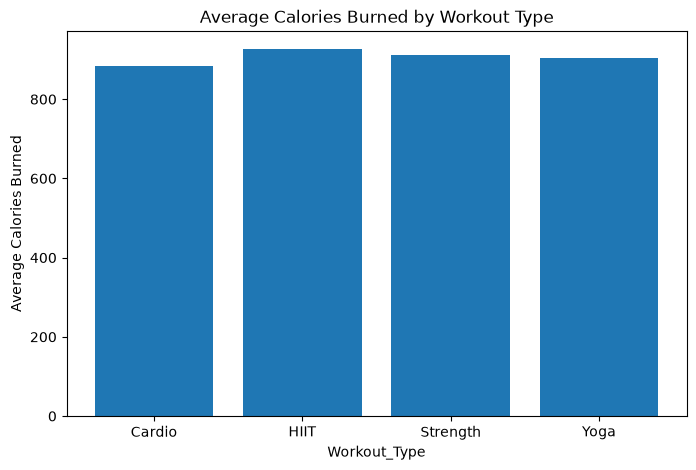

In [7]:

Workout_Calories = df.groupby('Workout_Type')['Calories_Burned'].mean()

plt.figure(figsize=(8, 5))
plt.bar(Workout_Calories.index,Workout_Calories.values)
plt.title("Average Calories Burned by Workout Type")
plt.xlabel("Workout_Type")
plt.ylabel("Average Calories Burned")
plt.show()


# Workout_Type


### Session Duration and Calories
Each point represents one workout session. This scatter plot helps inspect how session length and recorded calories vary together.


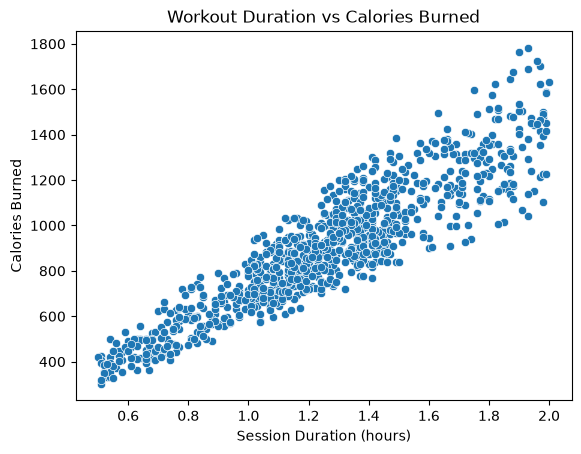

In [8]:
sns.scatterplot(
    data=df,
    x="Session_Duration (hours)",
    y="Calories_Burned"
)

plt.title("Workout Duration vs Calories Burned")
plt.xlabel("Session Duration (hours)")
plt.ylabel("Calories Burned")
plt.show()


### Average Heart Rate and Calories
Each point represents one session. The chart helps inspect the association between average heart rate and recorded calories.


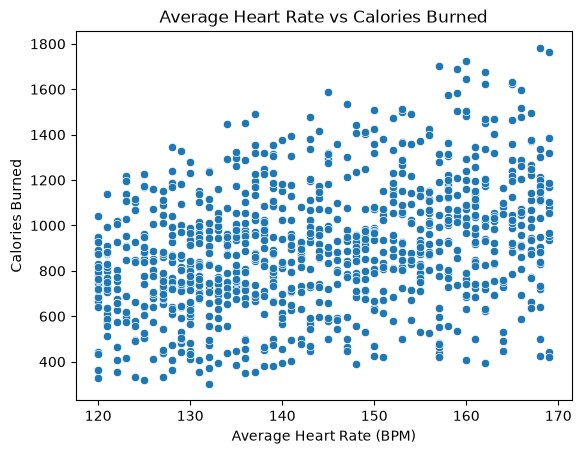

In [9]:
sns.scatterplot(
    data=df,
    x="Avg_BPM",
    y="Calories_Burned"
)

plt.title("Average Heart Rate vs Calories Burned")
plt.xlabel("Average Heart Rate (BPM)")
plt.ylabel("Calories Burned")
plt.show()


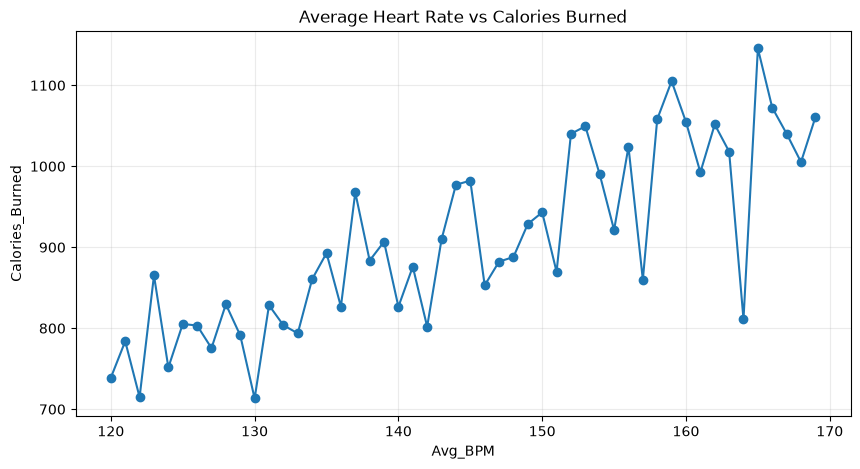

In [10]:
A_C = (
    df.groupby("Avg_BPM")["Calories_Burned"]
      .mean()
)


plt.figure(figsize=(10, 5))
plt.plot(A_C.index, A_C.values, marker="o")
plt.title("Average Heart Rate vs Calories Burned")
plt.xlabel("Avg_BPM")
plt.ylabel("Calories_Burned")
plt.grid(alpha=0.25)
plt.show()

### Calorie Distribution by Workout Type
Each box summarizes the distribution of recorded calories for one workout type. The center line is the median; the box shows the middle half of the observations.


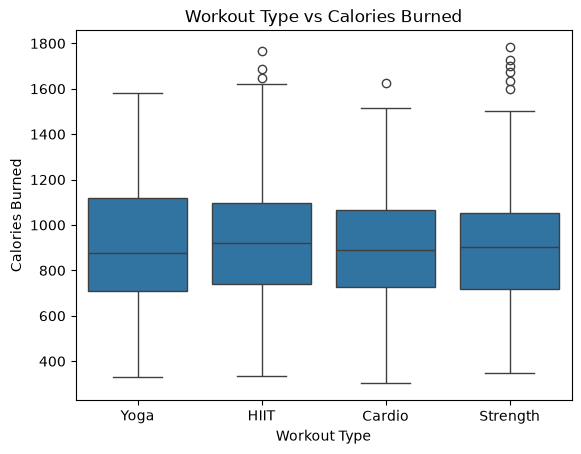

In [11]:
sns.boxplot(
    data=df,
    x="Workout_Type",
    y="Calories_Burned"
)

plt.title("Workout Type vs Calories Burned")
plt.xlabel("Workout Type")
plt.ylabel("Calories Burned")
plt.show()


In [12]:
df['Workout_Type'].value_counts()

Workout_Type
Strength    258
Cardio      255
Yoga        239
HIIT        221
Name: count, dtype: int64

### Weekly Workout Frequency and Calories
The box plots compare recorded calories across weekly workout-frequency groups. In this dataset, the group medians rise from roughly 720 calories at 2 days per week to roughly 1,270 at 5 days per week. This is an association in the data; session duration and intensity may also differ between groups.


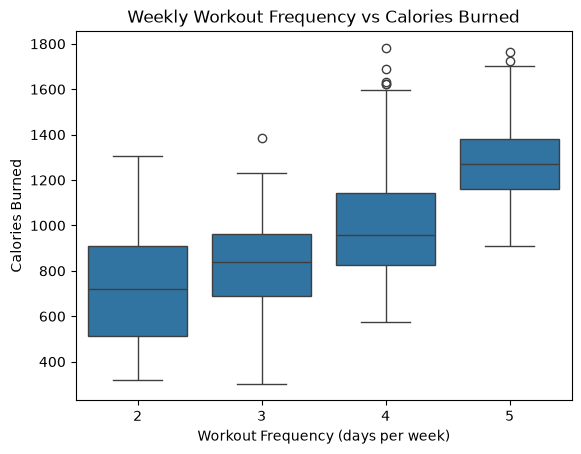

In [13]:
sns.boxplot(
    data=df,
    x="Workout_Frequency (days/week)",
    y="Calories_Burned"
)

plt.title("Weekly Workout Frequency vs Calories Burned")
plt.xlabel("Workout Frequency (days per week)")
plt.ylabel("Calories Burned")
plt.show()


## Define Features and Target, Then Split the Data
The data is split into training and test sets using an 80/20 split with `random_state=42`.


In [14]:
X = df.drop(columns = ['Calories_Burned'])
y = df['Calories_Burned']

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)
print("Train:", X_train.shape[0])
print("Test :", X_test.shape[0])

Train: 778
Test : 195


In [16]:
numeric_columns= X.select_dtypes(include=np.number).columns.tolist()
numeric_columns

['Age',
 'Weight (kg)',
 'Height (m)',
 'Max_BPM',
 'Avg_BPM',
 'Resting_BPM',
 'Session_Duration (hours)',
 'Fat_Percentage',
 'Water_Intake (liters)',
 'Workout_Frequency (days/week)',
 'Experience_Level',
 'BMI']

In [17]:
categorical_columns= X.select_dtypes(exclude=np.number).columns.tolist()
categorical_columns

['Gender', 'Workout_Type']

## Preprocessing
Categorical features are one-hot encoded. Numeric features are standardized for scale-sensitive models and passed through unchanged for tree-based models.


In [18]:
scaled_preprocessor=ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler() ,
            numeric_columns
        ) ,
        (
             "cat",
            OneHotEncoder(
                handle_unknown="ignore" ,
                sparse_output=False
            ) ,
            categorical_columns

        )
    ]

)



tree_preprocessor=ColumnTransformer(
    transformers=[
        (
            "num",
           "passthrough" ,
            numeric_columns
        ) ,
        (
             "cat",
            OneHotEncoder(
                handle_unknown="ignore" ,
                sparse_output=False
            ) ,
            categorical_columns

        )
    ]

)

## Candidate Regression Models
A Dummy regressor provides a simple baseline. Linear Regression, KNN, Decision Tree, SVR, and Random Forest are compared.


In [19]:
models={
    "Dummy":(
        tree_preprocessor,

        DummyRegressor(strategy="mean"),
    ) ,

     "Linear Regression":(
        scaled_preprocessor,

       LinearRegression(),
    ) ,
    "KNN":(
        scaled_preprocessor,
        KNeighborsRegressor(
            n_neighbors=5
        ),
    ) ,

        "Decision Tree":(
        tree_preprocessor,

       DecisionTreeRegressor(
           max_depth=10 ,
           min_samples_leaf=5 ,
           random_state=42

       ),
    ) ,

       "SVR":(
        scaled_preprocessor,

       SVR(
           kernel="rbf",
           C=100 ,
           epsilon=0.01 ,
        )
    ) ,

      "Random forest":(
        tree_preprocessor,

       RandomForestRegressor(
           n_estimators=200 ,
           min_samples_leaf=2,
           random_state=42,
           n_jobs=-1
       ),
    ) ,
}

## Supplemental Hyperparameter Search
GridSearchCV tests selected parameter combinations for Random Forest, SVR, and KNN using five-fold cross-validation on the training data. Mean absolute error is the selection metric. This is a supplemental experiment; its cross-validation scores are distinct from test-set scores.


In [20]:
param_grids = {
    "Random forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_leaf": [1, 2, 4]
    },

    "SVR": {
        "model__C": [1, 10, 100],
        "model__epsilon": [0.1, 1, 5],
        "model__gamma": ["scale", "auto"]
    },

    "KNN": {
        "model__n_neighbors": [3, 5, 7, 9, 11],
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2]
    }
}



The search fits the preprocessing and model together within each fold, reducing information leakage from preprocessing. The best parameter combination is selected by cross-validation MAE.


In [21]:
searches = {}
tuned_results = []

for name, param_grid in param_grids.items():
    preprocessor, model = models[name]

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="neg_mean_absolute_error",
        cv=5,
        n_jobs=1
    )

    search.fit(X_train, y_train)

    searches[name] = search

    tuned_results.append({
        "Model": name,
        "Best CV MAE": -search.best_score_,
        "Best Parameters": search.best_params_
    })


### Best Parameters from Cross-Validation


In [22]:
tuned_results_df = (
    pd.DataFrame(tuned_results)
    .sort_values("Best CV MAE")
    .reset_index(drop=True)
)

tuned_results_df


,Model,Best CV MAE,Best Parameters
0,SVR,33.938687,"{'model__C': 100, 'model__epsilon': 0.1, 'mode..."
1,Random forest,37.131255,"{'model__max_depth': None, 'model__min_samples..."
2,KNN,89.970954,"{'model__n_neighbors': 5, 'model__p': 2, 'mode..."


### Test-Set Results for Tuned Models
These scores evaluate the selected parameter settings on the held-out test split.


In [23]:
final_test_results = []

for name, search in searches.items():
    best_model = search.best_estimator_
    y_pred = best_model.predict(X_test)

    final_test_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    })

final_test_results_df = (
    pd.DataFrame(final_test_results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

final_test_results_df


,Model,MAE,RMSE,R2
0,SVR,35.391195,50.696866,0.969192
1,Random forest,36.752348,48.954674,0.971273
2,KNN,90.766059,117.935861,0.833277


## Baseline Model Comparison
The following models use the initial parameter settings defined above.


In [24]:
results=[]
fitted_models={}
predictions={}
for name, (preprocessor , model) in models.items():
    pipeLine=Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    pipeLine.fit(X_train,y_train)
    y_pred=pipeLine.predict(X_test)
    mae=mean_absolute_error(y_test,y_pred)
    rmse=np.sqrt(mean_squared_error(y_test,y_pred))
    r2=r2_score(y_test,y_pred)
    results.append( {
        "Model":name,
        "MAE":mae,
        "RMSE":rmse,
        "R2":r2
        }
    )
    fitted_models[name]=pipeLine
    predictions[name]=y_pred


### Baseline Test-Set Metrics


In [25]:
results_df=(pd.DataFrame(results).sort_values("R2", ascending=False)
            .reset_index(drop=True))


results_df.style.format({
    "MAE":"{:.2f}",
    "RMSE":"{:.2f}",
    "R2":"{:.3f}"
})
results_df

,Model,MAE,RMSE,R2
0,Linear Regression,30.270140,40.573095,0.980268
1,Random forest,36.752348,48.954674,0.971273
2,SVR,39.377276,57.018486,0.961030
3,Decision Tree,52.116577,68.795485,0.943269
4,KNN,91.978462,119.260407,0.829511
5,Dummy,231.204752,288.918127,-0.000583


### Interpreting R-squared
R-squared = 0.980 means the model explains about 98% of the variation in the target values on this test split. It does not mean the model is 98% accurate.


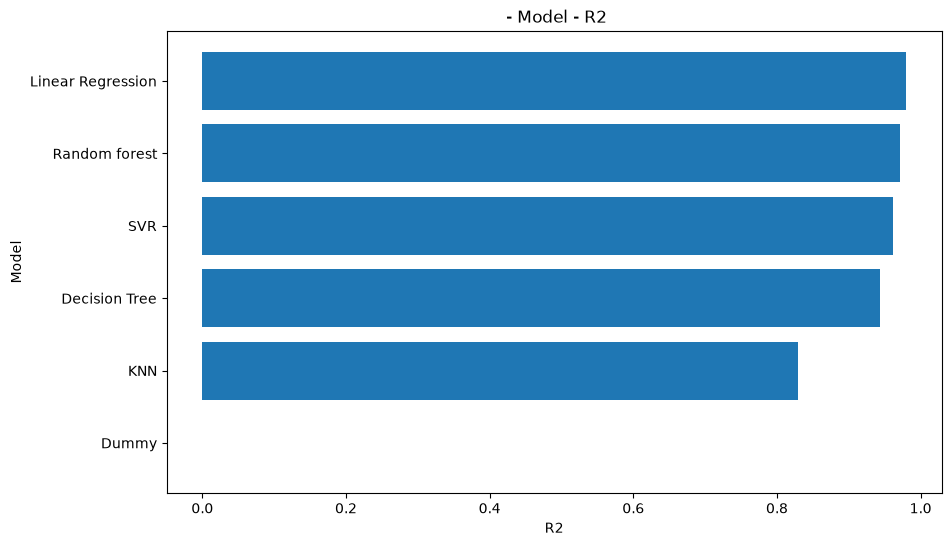

In [26]:
plot_df=results_df.sort_values("R2")
plt.figure(figsize=(10,6))
plt.barh(plot_df["Model"], plot_df["R2"])
plt.title(" - Model - R2")
plt.ylabel("Model")
plt.xlabel("R2")
plt.show()

### Interpreting MAE
MAE is the average absolute prediction error, measured in calories. Lower values indicate smaller average errors.


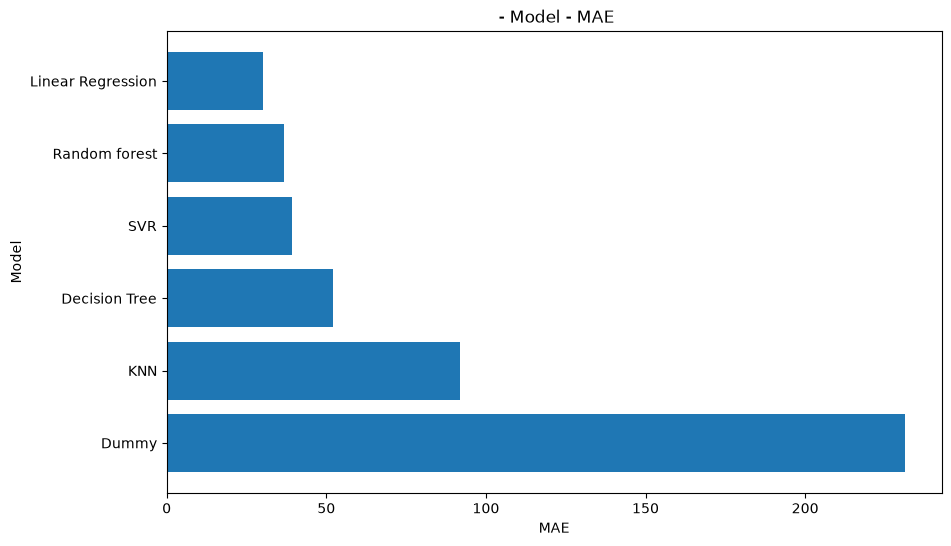

In [27]:
plot_df=results_df.sort_values("MAE",ascending=False)
plt.figure(figsize=(10,6))
plt.barh(plot_df["Model"], plot_df["MAE"])
plt.title(" - Model - MAE")
plt.ylabel("Model")
plt.xlabel("MAE")
plt.show()

## Error Analysis by Workout Type
The following table summarizes the selected Linear Regression model's errors for each workout category in the test set.


In [28]:
best_model_name = "Linear Regression"

test_results = pd.DataFrame(
    {
        "Workout_Type": X_test["Workout_Type"],
        "Actual": y_test,
        "Predicted": predictions[best_model_name]
    },
    index=X_test.index
)

test_results["Error"] = (
    test_results["Predicted"] - test_results["Actual"]
)


test_results["Absolute_Error"] = test_results["Error"].abs()


### Grouped Error Metrics
Sessions is the number of test observations in each group. MAE summarizes typical absolute error; RMSE gives greater weight to larger errors.


In [29]:
error_by_workout = (
    test_results
    .groupby("Workout_Type")
    .agg(
        Sessions=("Actual", "size"),
        Mean_Actual=("Actual", "mean"),
        Mean_Predicted=("Predicted", "mean"),
        MAE=("Absolute_Error", "mean"),
        RMSE=("Error", lambda errors: np.sqrt((errors ** 2).mean()))
    )
    .round(2)
    .sort_values("MAE")
)

error_by_workout


,Sessions,Mean_Actual,Mean_Predicted,MAE,RMSE
Workout_Type,,,,,
Strength,47,916.32,915.34,28.32,38.02
HIIT,42,933.57,923.29,29.60,41.28
Cardio,46,866.33,870.96,30.49,40.21
Yoga,60,925.28,924.42,32.10,42.25


### Error Analysis Findings
The model's MAE ranged from 28.32 calories for Strength to 32.10 calories for Yoga. The differences are modest, so no workout type stands out as substantially worse in this test split. Group sizes are limited, and these results do not guarantee the same performance on new data.


### Example Test-Set Predictions
Each row compares a held-out session's recorded calories with the model estimate. Difference is predicted minus actual: negative values indicate underestimation and positive values indicate overestimation. Absolute Error shows the size of the error regardless of direction. The displayed rows are examples; the overall MAE summarizes all test sessions.


In [30]:
best_model = fitted_models["Linear Regression"]

prediction_report = pd.DataFrame({
    "Workout_Type": X_test["Workout_Type"],
    "Actual_Calories": y_test,
    "Predicted_Calories": predictions["Linear Regression"]
}, index=X_test.index)


prediction_report["Difference"] = (prediction_report["Predicted_Calories"] - prediction_report["Actual_Calories"])


prediction_report["Absolute_Error"] = (prediction_report["Difference"].abs())

prediction_report.head(10)


,Workout_Type,Actual_Calories,Predicted_Calories,Difference,Absolute_Error
199,Cardio,929.0,913.292902,-15.707098,15.707098
538,HIIT,1401.0,1416.980086,15.980086,15.980086
174,Yoga,925.0,956.023330,31.023330,31.023330
464,Yoga,1155.0,1109.334421,-45.665579,45.665579
66,HIIT,1587.0,1504.428161,-82.571839,82.571839
424,HIIT,1247.0,1303.889503,56.889503,56.889503
718,Yoga,950.0,961.044150,11.044150,11.044150
346,Strength,927.0,938.783883,11.783883,11.783883
281,Yoga,1053.0,1039.390921,-13.609079,13.609079
158,Strength,1201.0,1195.974336,-5.025664,5.025664


## Save the Trained Pipeline
The fitted preprocessing and Linear Regression pipeline is saved for use by the API and Streamlit application.


### Verify the Saved Model File


In [31]:
import joblib

final_model = fitted_models["Linear Regression"]


joblib.dump(final_model, "../models/calorie_model.joblib")


['../models/calorie_model.joblib']

In [32]:
import os
print(os.getcwd())
print(os.path.exists("../models/calorie_model.joblib"))



E:\Machine Learning\gym 2\notebooks
True


### Example Feature Row
This displays the first input row from X without the target column.


In [33]:
X.iloc[[0]]


,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Workout_Type,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
0,56,Male,88.3,1.71,180,157,60,1.69,Yoga,12.6,3.5,4,3,30.2


## Train, Cross-Validation, and Test Performance
To check for overfitting, compare the selected Linear Regression pipeline on the training data, five-fold cross-validation within the training data, and the test data. The preprocessing remains inside the pipeline, so it is fitted separately within each cross-validation fold. A much lower training error than both cross-validation and test error can indicate overfitting; similar scores provide no clear evidence of strong overfitting, but do not prove it is absent.


In [34]:
train_prediction = final_model.predict(X_train)
test_prediction = final_model.predict(X_test)

linear_cv = cross_validate(
    final_model,
    X_train,
    y_train,
    cv=5,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    n_jobs=1
)

performance_comparison = pd.DataFrame([
    {
        "Data": "Train",
        "MAE": mean_absolute_error(y_train, train_prediction),
        "RMSE": np.sqrt(mean_squared_error(y_train, train_prediction)),
        "R2": r2_score(y_train, train_prediction)
    },
    {
        "Data": "5-fold CV mean (Train only)",
        "MAE": -linear_cv["test_MAE"].mean(),
        "RMSE": -linear_cv["test_RMSE"].mean(),
        "R2": linear_cv["test_R2"].mean()
    },
    {
        "Data": "Test",
        "MAE": mean_absolute_error(y_test, test_prediction),
        "RMSE": np.sqrt(mean_squared_error(y_test, test_prediction)),
        "R2": r2_score(y_test, test_prediction)
    }
]).round(3)

performance_comparison


,Data,MAE,RMSE,R2
0,Train,29.560,38.951,0.979
1,5-fold CV mean (Train only),30.467,40.000,0.978
2,Test,30.270,40.573,0.980


The scores are close: MAE is 29.56 on Train, 30.47 for the mean of five cross-validation folds, and 30.27 on Test. This gives no clear evidence of strong overfitting on this split, but it cannot prove that overfitting is absent. The test data was also used earlier during model comparison.


## Permutation Feature Importance
Permutation importance measures how much the model score worsens when one input column is shuffled. A larger increase in MAE means the model relied more on that feature for this test split. This is a model-specific association, not proof of cause and effect. Correlated inputs can share or mask importance. The test split was already used during model comparison, so this analysis is exploratory.


In [35]:
from sklearn.inspection import permutation_importance

permutation_result = permutation_importance(
    estimator=final_model,
    X=X_test,
    y=y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=20,
    random_state=42,
    n_jobs=1
)

feature_importance = (
    pd.DataFrame({
        "Feature": X_test.columns,
        "MAE increase (calories)": permutation_result.importances_mean,
        "Variation": permutation_result.importances_std
    })
    .sort_values("MAE increase (calories)", ascending=False)
    .reset_index(drop=True)
)

feature_importance.round(2)


,Feature,MAE increase (calories),Variation
0,Session_Duration (hours),263.86,12.12
1,Avg_BPM,76.31,4.66
2,Age,29.48,2.50
3,Gender,27.63,2.28
4,BMI,11.39,1.31
5,Weight (kg),8.91,1.24
6,Height (m),3.49,0.69
7,Experience_Level,0.33,0.21
8,Water_Intake (liters),0.09,0.10
9,Fat_Percentage,0.01,0.25


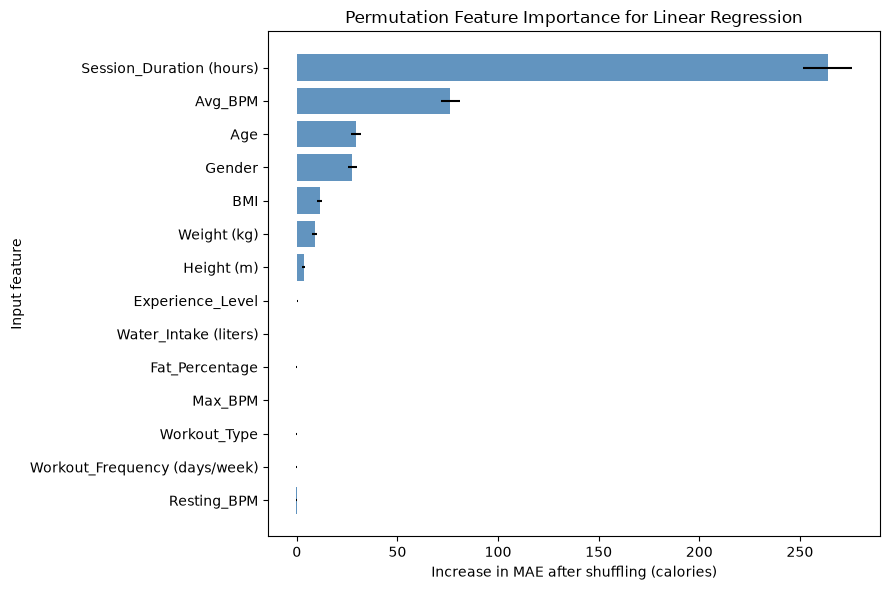

In [36]:
plot_importance = feature_importance.sort_values("MAE increase (calories)")

plt.figure(figsize=(9, 6))
plt.barh(
    plot_importance["Feature"],
    plot_importance["MAE increase (calories)"],
    xerr=plot_importance["Variation"],
    color="steelblue",
    alpha=0.85
)
plt.title("Permutation Feature Importance for Linear Regression")
plt.xlabel("Increase in MAE after shuffling (calories)")
plt.ylabel("Input feature")
plt.tight_layout()
plt.show()


Session duration had the largest permutation importance, followed by average heart rate (`Avg_BPM`). Workout frequency showed a positive relationship with calories in the exploratory plots, but its additional contribution was close to zero in this model when the other inputs were included. This ranking is model- and split-specific, and correlated features can share importance.


## Limitations and Conclusion
Linear Regression had the strongest results in the initial model comparison on this split (MAE 30.27 calories, RMSE 40.57 calories, R-squared 0.980). These metrics describe this dataset split and are not a guarantee of performance on future sessions.

The test set was used to compare candidate models, evaluate tuned models, and calculate permutation importance, so it was not completely untouched during model selection. The reported test scores and importance ranking are exploratory and may be optimistic. The target values are the dataset's recorded calories; this project does not independently verify how those values were measured. All predictions should be treated as estimates, not definite measurements.


In [37]:
# python -m uvicorn app.api:app --reload
# python -m streamlit run app/streamlit_app.py
